# Does Ramen's cache help once its entries point toward their true labels?

**Question.** Filing Ramen's cache by the true label (every queue pure) made DomainNet accuracy *worse* than
Ramen: 55.29% vs 56.80%, with quickdraw at 11.05% vs 17.54% (`2026-10-23_cache_contamination`,
`2026-11-01_pillow_sink`). The proposed reason: a queue's label never reaches the update. Every entry stores the
image's own **entropy** gradient, which sharpens its *zero-shot* prediction, right or wrong. If so, giving the
entries a gradient toward their **true** label should turn the oracle into a large gain. If it does not, the
explanation (or the oracle pipeline) is wrong.

**Design: two factors, crossed.** Ramen makes two choices about the cache; each is replaced by an oracle choice.

| | value = own entropy gradient (Ramen) | value = cross-entropy gradient toward the true label (ORACLE) |
|---|---|---|
| **filed by zero-shot prediction (Ramen)** | `Ramen` (cached) | `labeloracle_zs_ce` (new) |
| **filed by true label (ORACLE)** | `oracle_file_true` (cached, 2026-10-23) | `labeloracle_true_ce` (new) |

All four runs use true labels except Ramen: **the three oracles are upper bounds, not methods.**

**No image uses its own label.** Ramen writes each image into the cache *before* retrieval, so an image always
retrieves its own entry (distance 0). Here an entry is written with the entropy gradient, as in Ramen; its label
is revealed only *after* the image is predicted, and only then is its value replaced by the label gradient. So
each prediction uses the labels of earlier images only (an online stream with label feedback after each batch).
Retrieval weights, retrieval, the signSGD step and the reset are Ramen's.

**Hypotheses (written before the full runs).**
- **H1.** `labeloracle_true_ce` beats Ramen by more than the noise floor (0.11 points), by several points.
- **H2.** Label values matter more than filing: `labeloracle_zs_ce` also beats Ramen by more than the floor, and
  the filing factor changes accuracy far less than the value factor.
- **H3.** The *pillow* sink shrinks: label-value runs predict *pillow* wrongly far less often than Ramen's 6,484.

**Data.** DomainNet, 6 domains, 345 classes, 596,006 images; CLIP ViT-B/32; one mixed (shuffled) stream, batch
size 100. Config `cfg/DomainNet/Ramen.yaml` (capacity 300, top-k 10, β 5, signSGD lr 0.01, fp16 priorities),
unchanged for every run.

**Seeds.** Seed 0 only (screening). A seed sets the order of the stream; all runs here share seed 0's stream.
Noise floor = 2 × (max − min) of Ramen over seeds 0–4.

**How the runs were produced.** New code in this folder only (`label_methods.py`: `RamenLabelValues`, a subclass
of `RamenTrueLabel`, built through a local registry; nothing in `src/` or `cfg/` is changed):
```
python run_label_oracle.py DomainNet 0 --smoke smoke                                   # sanity check, 1,200 images
CUDA_VISIBLE_DEVICES=0 python run_label_oracle.py DomainNet 0 --runs labeloracle_true_ce
CUDA_VISIBLE_DEVICES=1 python run_label_oracle.py DomainNet 0 --runs labeloracle_zs_ce
```
Results are cached in `new_experiments/results/` and loaded below.

**What counts as a result.** A change vs Ramen larger than the noise floor, in domain-averaged accuracy.

**Sections.** 1 Setup · 2 Data · 3 Sanity checks · 4 Results (2 × 2, per domain, adapted filing, global retrieval) ·
5 Mechanism: what each filing retrieves, the neighbours' labels, near-copies · 6 The *pillow* sink · 7 Interpretation ·
8 Glossary


## 1. Setup

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')  # everything below reads cached runs

import pandas as pd
from IPython.display import display

from label_oracle import FULL_RUNS, LABELS, NEW_RUNS, SMOKE_CHECKS, SMOKE_RUNS, LabelOracleExperiment
from true_label_cache import count_pct, noise_floor, seed_table
import plots

pd.set_option('display.width', 220, 'display.max_columns', 20)
exp = LabelOracleExperiment('DomainNet', seed=0).run_all(FULL_RUNS)
ORACLES = list(FULL_RUNS[2:])  # the three oracle runs, compared with Ramen

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


oracle_file_true: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_oracle_file_true.pkl
labeloracle_zs_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_labeloracle_zs_ce.pkl
labeloracle_true_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_labeloracle_true_ce.pkl


## 2. The data the code ran on

Images and classes per domain, and how many zero-shot CLIP gets right: the denominators of everything below.

In [2]:
exp.data_table()

,images,classes,NoAdapt correct
domain,,,
clipart,48833,345,"33,328 of 48,833 (68.2%)"
infograph,53201,345,"23,354 of 53,201 (43.9%)"
painting,75759,345,"48,924 of 75,759 (64.6%)"
quickdraw,172500,345,"22,992 of 172,500 (13.3%)"
real,175327,345,"143,982 of 175,327 (82.1%)"
sketch,70386,345,"42,265 of 70,386 (60.0%)"
all,596006,345,"314,845 of 596,006 (52.8%)"


## 3. Sanity checks

### 3.1 The "off" settings reproduce their references exactly

On 200 images per domain (1,200), `RamenLabelValues` with Ramen's value (entropy) must give the same predictions as Ramen (zero-shot filing) and as `RamenTrueLabel` (true-label filing): 100.00%.

In [3]:
smoke = LabelOracleExperiment('DomainNet', seed=0, n_per_domain=200, results_dir='smoke').run_all(SMOKE_RUNS)
assert all(smoke.sanity_check(a, b) for a, b in SMOKE_CHECKS), 'off settings differ from their references'
smoke.summary_table(list(SMOKE_RUNS))

NoAdapt: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n200_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n200_bs100_s0_Ramen.pkl
labeloracle_off: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n200_bs100_s0_labeloracle_off.pkl
RamenTrueLabel_true: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n200_bs100_s0_RamenTrueLabel_true.pkl
labeloracle_true_entropy: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n200_bs100_s0_labeloracle_true_entropy.pkl
labeloracle_zs_ce: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n200_bs100_s0_labeloracle_zs_ce.pkl
labeloracle_true_ce: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n200_bs100_s0_labeloracle_true_ce.pkl
late_zs_entropy: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n200_bs100_s0_late_zs_entropy.pkl
late_zs_ce: loaded cached results from smoke/DomainNet_clip_vitbase32_mixed_n2

,correct,acc (domain avg),vs Ramen (pts),vs Ramen (images),fixed vs NoAdapt,broken vs NoAdapt,same pred as Ramen
NoAdapt,"687 of 1,200 (57.2%)",57.25,-1.42,-17,"0 of 1,200 (0.0%)","0 of 1,200 (0.0%)",89.42%
Ramen,"704 of 1,200 (58.7%)",58.67,+0.00,+0,"28 of 1,200 (2.3%)","11 of 1,200 (0.9%)",100.00%
labeloracle_off,"704 of 1,200 (58.7%)",58.67,+0.00,+0,"28 of 1,200 (2.3%)","11 of 1,200 (0.9%)",100.00%
RamenTrueLabel_true,"705 of 1,200 (58.8%)",58.75,+0.08,+1,"28 of 1,200 (2.3%)","10 of 1,200 (0.8%)",97.92%
labeloracle_true_entropy,"705 of 1,200 (58.8%)",58.75,+0.08,+1,"28 of 1,200 (2.3%)","10 of 1,200 (0.8%)",97.92%
labeloracle_zs_ce,"713 of 1,200 (59.4%)",59.42,+0.75,+9,"36 of 1,200 (3.0%)","10 of 1,200 (0.8%)",92.92%
labeloracle_true_ce,"711 of 1,200 (59.2%)",59.25,+0.58,+7,"35 of 1,200 (2.9%)","11 of 1,200 (0.9%)",93.33%
late_zs_entropy,"688 of 1,200 (57.3%)",57.33,-1.33,-16,"23 of 1,200 (1.9%)","22 of 1,200 (1.8%)",90.00%
late_zs_ce,"693 of 1,200 (57.8%)",57.75,-0.92,-11,"30 of 1,200 (2.5%)","24 of 1,200 (2.0%)",83.58%
late_adapted_entropy,"688 of 1,200 (57.3%)",57.33,-1.33,-16,"23 of 1,200 (1.9%)","22 of 1,200 (1.8%)",89.92%


### 3.2 The label value points toward the true label

One signSGD step on each image's *own* stored value, on one batch of 100 images (`check_label_gradient.py`). The CE value should raise the probability of the true class; Ramen's entropy value raises the probability of the zero-shot class.

In [4]:
print(open('logs/check_label_gradient.log').read())

100 images; zero-shot correct on 62; mean cosine(entropy value, CE value) = +0.482
entropy (Ramen): p(class it targets) rises on 90 of 100, mean +0.247; correct 62 -> 64 of 100
CE toward true label (oracle): p(class it targets) rises on 97 of 100, mean +0.348; correct 62 -> 97 of 100



### 3.3 The full runs

Same stream as Ramen; the labels the method saw agree with the scored labels (its count of zero-shot errors equals the zero-shot model's); and every written entry got its label value.

In [5]:
keys = ['domain_idx', 'sample_idx']
ram = exp.results['Ramen'][keys].to_numpy()
zs_wrong = int((~exp.results['NoAdapt']['correct']).sum())
rows = []
for n in NEW_RUNS:
    st = exp.stats[n]
    rows.append({'run': n,
                 'same stream as Ramen': bool((exp.results[n][keys].to_numpy() == ram).all()),
                 'zero-shot errors the method counted': f"{sum(st['zs_wrong']):,}",
                 'zero-shot errors (NoAdapt)': f'{zs_wrong:,}',
                 'entries given a label value': count_pct(sum(st['revealed']), len(ram))})
pd.DataFrame(rows).set_index('run')

,same stream as Ramen,zero-shot errors the method counted,zero-shot errors (NoAdapt),entries given a label value
run,,,,
labeloracle_zs_ce,True,"281,166","281,161","168,502 of 596,006 (28.3%)"
labeloracle_true_ce,True,"281,166","281,161","169,020 of 596,006 (28.4%)"


The method counts 5 more zero-shot errors than NoAdapt (281,166 vs 281,161): fp16 rounding between the two forward passes on near-ties. Only 28% of entries ever get a label value because only 28% of images are ever stored: after Ramen's fp16 arrival counter saturates (65,520), new entries replace each full queue's older ones once and then the queues stop changing (see `2026-11-01_pillow_sink`). This holds for every run here, Ramen included.

### 3.4 Noise floor

In [6]:
seeds = seed_table('DomainNet', ('Ramen',))
floor = noise_floor(seeds['Ramen'])
print(f'Ramen over seeds 0-4: {seeds.Ramen.round(2).tolist()} -> noise floor {floor:.2f} points')

Ramen over seeds 0-4: [56.8, 56.79, 56.83, 56.81, 56.85] -> noise floor 0.11 points


## 4. Results

### 4.1 One row per run

Domain-averaged accuracy; counts are pooled over all 596,006 images. Fixed / broken are relative to zero-shot.

In [7]:
exp.summary_table(list(FULL_RUNS))

,correct,acc (domain avg),vs Ramen (pts),vs Ramen (images),fixed vs NoAdapt,broken vs NoAdapt,same pred as Ramen
NoAdapt,"314,845 of 596,006 (52.8%)",55.37,-1.43,"-10,121","0 of 596,006 (0.0%)","0 of 596,006 (0.0%)",78.23%
Ramen,"324,966 of 596,006 (54.5%)",56.8,+0.00,+0,"20,419 of 596,006 (3.4%)","10,298 of 596,006 (1.7%)",100.00%
oracle_file_true,"312,149 of 596,006 (52.4%)",55.29,-1.50,"-12,817","11,056 of 596,006 (1.9%)","13,752 of 596,006 (2.3%)",79.99%
labeloracle_zs_ce,"337,173 of 596,006 (56.6%)",58.5,+1.70,"+12,207","33,871 of 596,006 (5.7%)","11,543 of 596,006 (1.9%)",74.92%
labeloracle_true_ce,"323,959 of 596,006 (54.4%)",56.54,-0.25,"-1,007","26,131 of 596,006 (4.4%)","17,017 of 596,006 (2.9%)",72.27%


### 4.2 The 2 × 2: filing × value

In [8]:
ft = exp.factor_table()
display(ft)
d = ft['vs Ramen (pts)']
value_effect = (d[('zero-shot', 'true-label CE')] + d[('true label', 'true-label CE')]
                - d[('zero-shot', 'entropy')] - d[('true label', 'entropy')]) / 2
filing_effect = (d[('true label', 'entropy')] + d[('true label', 'true-label CE')]
                 - d[('zero-shot', 'entropy')] - d[('zero-shot', 'true-label CE')]) / 2
print(f'main effect of label values: {value_effect:+.2f} pts; main effect of true-label filing: {filing_effect:+.2f} pts')

,,run,acc (domain avg),vs Ramen (pts),vs Ramen (images)
filing,value,,,,
zero-shot,entropy,Ramen,56.80,0.00,0
true label,entropy,oracle_file_true,55.29,-1.50,-12817
zero-shot,true-label CE,labeloracle_zs_ce,58.50,1.70,12207
true label,true-label CE,labeloracle_true_ce,56.54,-0.25,-1007


main effect of label values: +1.48 pts; main effect of true-label filing: -1.73 pts


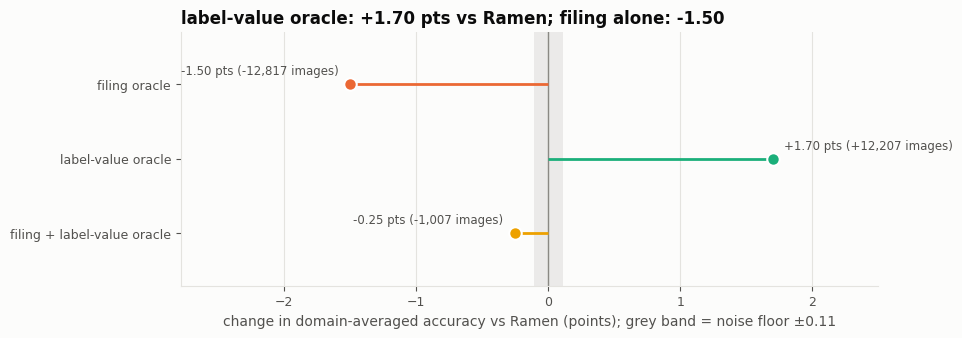

In [9]:
by_run = ft.reset_index().set_index('run')['vs Ramen (pts)']
best = by_run[ORACLES].idxmax()
title = f"{LABELS[best]}: {by_run[best]:+.2f} pts vs Ramen; filing alone: {by_run['oracle_file_true']:+.2f}"
plots.plot_vs_ramen(exp, ORACLES, floor, title=title);

### 4.3 Per domain

In [10]:
exp.accuracy_table(list(FULL_RUNS))

,NoAdapt,Ramen,oracle_file_true,labeloracle_zs_ce,labeloracle_true_ce
domain,,,,,
clipart,68.25,69.33,68.61,70.93,69.17
infograph,43.90,44.98,44.52,45.56,44.54
painting,64.58,65.70,65.56,67.10,65.25
quickdraw,13.33,17.54,11.05,21.56,17.34
real,82.12,82.27,82.20,83.50,82.45
sketch,60.05,60.96,59.83,62.32,60.49
domain avg,55.37,56.80,55.29,58.50,56.54


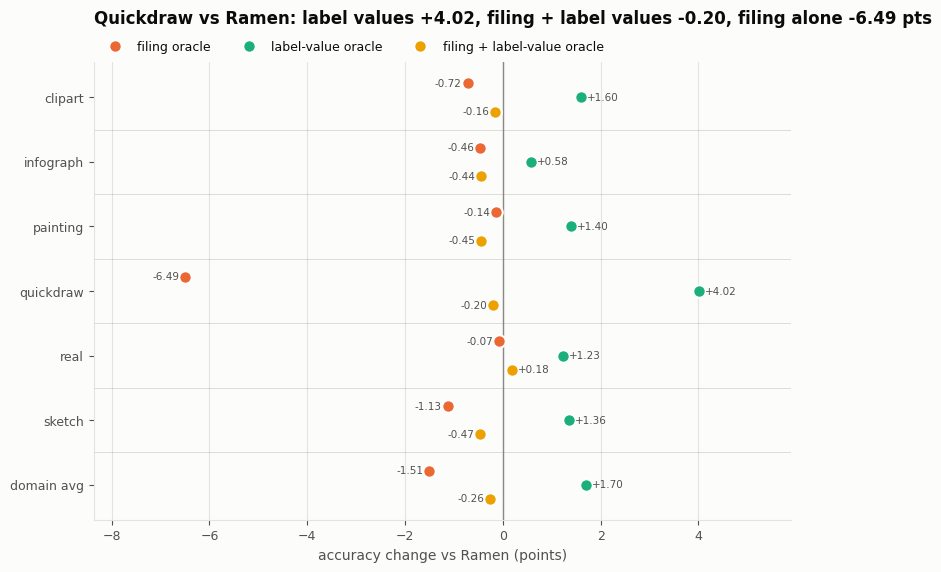

In [11]:
delta = exp.accuracy_table(ORACLES + ['Ramen'])
qd = delta.loc['quickdraw']
plots.plot_domain_change(exp, ORACLES, title=f"Quickdraw vs Ramen: label values {qd['labeloracle_zs_ce'] - qd['Ramen']:+.2f}, "
                         f"filing + label values {qd['labeloracle_true_ce'] - qd['Ramen']:+.2f}, "
                         f"filing alone {qd['oracle_file_true'] - qd['Ramen']:+.2f} pts");

Fixed and broken images vs Ramen, per domain, for the two label-value runs:

In [12]:
for n in NEW_RUNS:
    print(LABELS[n])
    display(exp.change_table(n, baseline='Ramen'))

label-value oracle


,Ramen,labeloracle_zs_ce,images,fixed,broken,net (images),share of net gain
domain,,,,,,,
clipart,69.33,70.93,48833,1834,1055,779,6.4%
infograph,44.98,45.56,53201,1546,1238,308,2.5%
painting,65.70,67.10,75759,2507,1440,1067,8.7%
quickdraw,17.54,21.56,172500,14148,7214,6934,56.8%
real,82.27,83.50,175327,4640,2480,2160,17.7%
sketch,60.96,62.32,70386,2787,1828,959,7.9%
domain avg,56.80,58.50,<NA>,<NA>,<NA>,<NA>,NaN


filing + label-value oracle


,Ramen,labeloracle_true_ce,images,fixed,broken,net (images),share of net gain
domain,,,,,,,
clipart,69.33,69.17,48833,1596,1672,-76,7.5%
infograph,44.98,44.54,53201,1393,1628,-235,23.3%
painting,65.70,65.25,75759,2114,2450,-336,33.4%
quickdraw,17.54,17.34,172500,10738,11081,-343,34.1%
real,82.27,82.45,175327,3894,3582,312,-31.0%
sketch,60.96,60.49,70386,2311,2640,-329,32.7%
domain avg,56.80,56.54,<NA>,<NA>,<NA>,<NA>,NaN


### 4.4 A third filing rule: the adapted prediction

The Ramen paper (Sec. 3.2) and its code file each image under its **zero-shot** prediction. Filing under the
**adapted** prediction instead (Ramen's own output, more often right) needs the write moved *after* prediction,
because the adapted prediction exists only after retrieval and the step (`RamenWriteAfterPrediction`). That also
changes two things besides filing: an image no longer retrieves its own entry or later images of its batch, and
the first batch (empty cache) is predicted zero-shot. So each adapted run has a **timing control**: zero-shot
filing with the same late write.

| run | write | filing | value | uses labels? |
|---|---|---|---|---|
| `late_zs_entropy` | after prediction | zero-shot | entropy | no (timing control for Ramen) |
| `late_zs_ce` | after prediction | zero-shot | true-label CE | oracle (timing control) |
| `late_adapted_entropy` | after prediction | **adapted** | entropy | **no: a method** |
| `late_adapted_ce` | after prediction | **adapted** | true-label CE | oracle |

Checks (`check_write_after.py`, first 3,000 DomainNet images): the first batch is not adapted and equals zero-shot;
retrieval sees earlier batches only; every image is written to the queue of the class the method returned
(adapted filing) or its zero-shot class; 485 of 3,000 images are filed differently by the two rules.

In [13]:
from label_oracle import LATE_RUNS
exp.run_all(LATE_RUNS)
ft3 = exp.filing_table()
ft3

late_zs_entropy: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_late_zs_entropy.pkl
late_zs_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_late_zs_ce.pkl
late_adapted_entropy: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_late_adapted_entropy.pkl
late_adapted_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_late_adapted_ce.pkl


run  uses labels  acc (domain avg)  vs Ramen (pts)  vs Ramen (images)
write                    filing     value                                                                                                
before retrieval (Ramen) zero-shot  entropy                       Ramen        False             56.80            0.00                  0
                         true label entropy            oracle_file_true         True             55.29           -1.50             -12817
                         zero-shot  true-label CE     labeloracle_zs_ce         True             58.50            1.70              12207
                         true label true-label CE   labeloracle_true_ce         True             56.54           -0.25              -1007
after prediction         zero-shot  entropy             late_zs_entropy        False             56.74           -0.05               -236
                                    true-label CE            late_zs_ce         True             58.66            1.86              13158
                         adapted    entropy        late_adapted_entropy        False             56.53           -0.27              -2639
                                    true-label CE       late_adapted_ce         True             58.06            1.26               9182

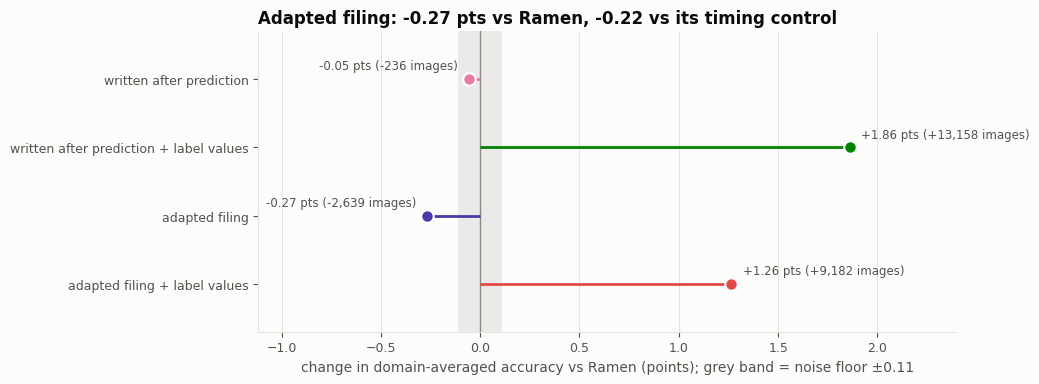

In [14]:
v = ft3.reset_index().set_index('run')['vs Ramen (pts)']
plots.plot_vs_ramen(exp, list(LATE_RUNS), floor,
                    title=f"Adapted filing: {v['late_adapted_entropy']:+.2f} pts vs Ramen, "
                          f"{v['late_adapted_entropy'] - v['late_zs_entropy']:+.2f} vs its timing control");

Per domain: Ramen, its timing control, and adapted filing (both with entropy values).

In [15]:
late = exp.accuracy_table(['Ramen', 'late_zs_entropy', 'late_adapted_entropy'], by='domain')
late['adapted − timing control'] = late['late_adapted_entropy'] - late['late_zs_entropy']
late.round(2)

,Ramen,late_zs_entropy,late_adapted_entropy,adapted − timing control
domain,,,,
clipart,69.33,69.23,69.31,0.08
infograph,44.98,44.89,44.83,-0.06
painting,65.70,65.68,65.78,0.10
quickdraw,17.54,17.51,15.94,-1.57
real,82.27,82.26,82.35,0.09
sketch,60.96,60.89,60.99,0.10
domain avg,56.80,56.74,56.53,-0.21


### 4.5 Global top-k retrieval: is the queue-averaged vote the bottleneck?

Ramen takes the top-k entries of **every** non-empty class queue and averages them, so most of an update comes
from classes the image is not. `RamenGlobalRetrieval` with `retrieval: global_knn` keeps everything else (filing,
values, timing, weights e^(−H)·e^(−β·d)) and instead takes the **k nearest entries of the whole cache**, normalised
by their total weight.

| run | retrieval | value | uses labels? |
|---|---|---|---|
| `labeloracle_zs_ce` | top-k per queue (Ramen) | true-label CE | oracle |
| `global_ce_k10`, `global_ce_k100`, `global_ce_k1000` | k nearest overall | true-label CE | oracle |
| `global_entropy_k100` | 100 nearest overall | entropy | **no: a method** |

Check: with `retrieval: per_class` (`global_off`) the class reproduces Ramen on every smoke image (section 3.1).


In [16]:
from label_oracle import GLOBAL_RUNS
exp.run_all(GLOBAL_RUNS)
gt = exp.vs_table(['labeloracle_zs_ce', *GLOBAL_RUNS], baselines=('Ramen', 'labeloracle_zs_ce'))
gt

global_ce_k10: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_global_ce_k10.pkl
global_ce_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_global_ce_k100.pkl
global_ce_k1000: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_global_ce_k1000.pkl
global_entropy_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_global_entropy_k100.pkl


,label,acc (domain avg),vs Ramen (pts),vs Ramen (images),vs labeloracle_zs_ce (pts),vs labeloracle_zs_ce (images)
run,,,,,,
labeloracle_zs_ce,label-value oracle,58.50,1.70,12207,0.00,0
global_ce_k10,global k=10 + label values,59.65,2.86,22366,1.16,10159
global_ce_k100,global k=100 + label values,59.34,2.54,18947,0.85,6740
global_ce_k1000,global k=1000 + label values,58.63,1.84,12264,0.14,57
global_entropy_k100,global k=100 (no labels),56.83,0.04,-1068,-1.66,-13275


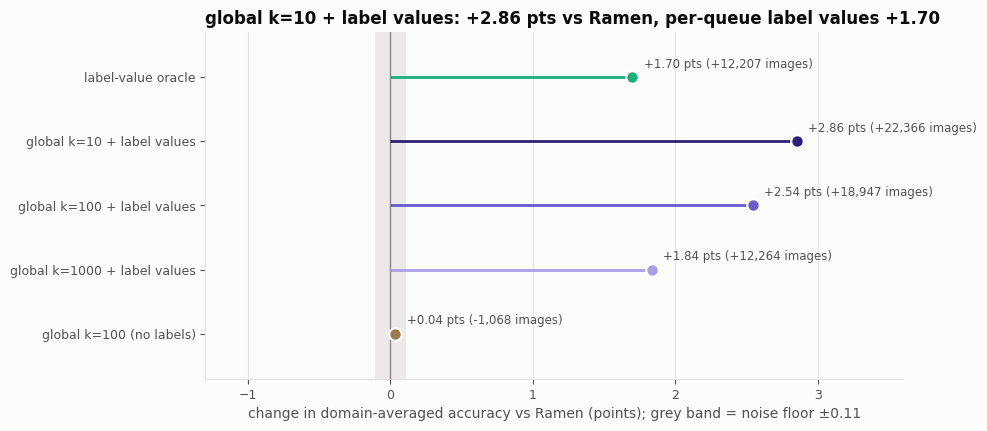

In [17]:
g = gt['vs Ramen (pts)']
best = g[list(GLOBAL_RUNS)].idxmax()
plots.plot_vs_ramen(exp, ['labeloracle_zs_ce', *GLOBAL_RUNS], floor,
                    title=f"{LABELS[best]}: {g[best]:+.2f} pts vs Ramen, per-queue label values "
                          f"{g['labeloracle_zs_ce']:+.2f}");

Per domain:

In [18]:
gacc = exp.accuracy_table(['Ramen', 'labeloracle_zs_ce', *GLOBAL_RUNS], by='domain')
gacc.round(2)

,Ramen,labeloracle_zs_ce,global_ce_k10,global_ce_k100,global_ce_k1000,global_entropy_k100
domain,,,,,,
clipart,69.33,70.93,71.30,71.37,71.22,69.59
infograph,44.98,45.56,46.01,46.13,46.20,45.21
painting,65.70,67.10,67.53,67.75,67.61,65.85
quickdraw,17.54,21.56,27.04,25.01,21.34,16.40
real,82.27,83.50,83.33,83.32,83.36,82.30
sketch,60.96,62.32,62.71,62.47,62.07,61.65
domain avg,56.80,58.50,59.65,59.34,58.63,56.83


## 5. Mechanism: what each filing rule retrieves

### 5.1 How the update weight splits over classes

Retrieval never depends on the stored values: an entry's weight is e^(−H)·e^(−β·d) from its zero-shot entropy and
feature. So the offline cache replay of `2026-11-01_pillow_sink` (exact, CPU) gives the entries the label-value
runs retrieved. With label values, each entry pushes toward *its* true class, so for 1,000 random images (after
the first 20% of the stream) we measure, per image, how the update weight splits over the entries' true classes:

- **share on own true class**: the weight that pushes toward the right class;
- **own class is the largest**: the image's true class gets more weight than any other single class (a
  plurality proxy for whether the step's direction favours the right class);
- **effective number of classes**: exp(entropy) of the weight split over classes (345 = perfectly spread);
- **share from own domain**.

Caveat: this counts weight, not gradient direction. Gradients toward similar classes partly agree, so it is a
proxy for the step's direction, not the step itself.


In [19]:
from mechanism import LabelAgreement
agree = LabelAgreement('DomainNet', seed=0, n=1000)
mech = agree.by_domain()
mech

queries  share on own true class %  share on largest single class %  own class is the largest %  effective number of classes  share from own domain %
domain       filing                                                                                                                                                                  
clipart      true-label filing       79                        2.6                              3.2                        49.4                        222.1                     36.1
             zero-shot filing        79                        2.6                              2.9                        53.2                        230.6                     42.4
infograph    true-label filing       83                        1.7                              2.4                        25.3                        255.9                     39.1
             zero-shot filing        83                        2.0                              2.4                        34.9                        249.2                     38.8
painting     true-label filing      121                        2.3                              2.9                        46.3                        225.4                     49.0
             zero-shot filing       121                        2.4                              2.9                        50.4                        226.3                     50.8
quickdraw    true-label filing      301                        1.3                              2.6                        11.3                        275.7                    100.0
             zero-shot filing       301                        1.5                              2.3                        20.3                        235.9                     68.9
real         true-label filing      289                        3.6                              3.9                        67.8                        225.3                     63.1
             zero-shot filing       289                        3.8                              4.0                        72.7                        231.6                     63.6
sketch       true-label filing      127                        2.4                              3.3                        36.2                        224.4                     38.8
             zero-shot filing       127                        2.1                              2.7                        41.7                        225.8                     46.4
all (pooled) true-label filing     1000                        2.4                              3.1                        39.2                        242.6                     65.3
             zero-shot filing      1000                        2.5                              3.0                        45.6                        232.9                     57.7

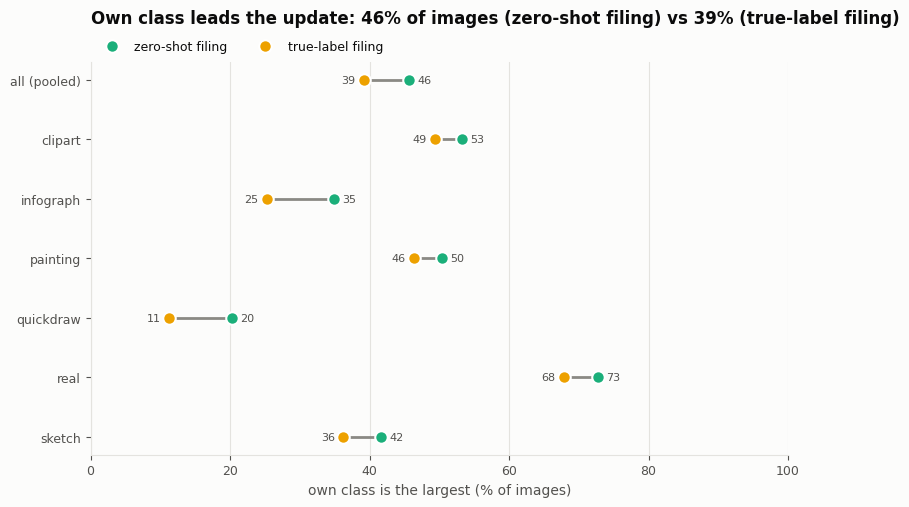

In [20]:
m = mech['own class is the largest %'].unstack('filing')
plots.plot_agreement(mech, title=f"Own class leads the update: {m.loc['all (pooled)', 'zero-shot filing']:.0f}% of images "
                     f"(zero-shot filing) vs {m.loc['all (pooled)', 'true-label filing']:.0f}% (true-label filing)");

### 5.2 How often the nearest entries carry the right label

With label values, each retrieved entry pushes toward its own true class, so an update can point the right way
only as often as the retrieved entries vote for the image's class. `NeighbourLabels` replays Ramen's cache for
2,000 random images (after the first 20% of the stream) and takes the retrieval-weighted vote of the entries' true
labels: over Ramen's active set (10 per queue) and over the 10 nearest entries overall.

In [21]:
from neighbour_labels import NeighbourLabels
nl = NeighbourLabels('DomainNet', seed=0, n=2000)
nls = nl.summary()
nls

,images,zero-shot right,Ramen right,per-queue vote right,per-queue share on own class %,global-10 vote right,global-10 share on own class %,global-10 neighbours of own class,labeloracle_zs_ce right,global_ce_k10 right,global_ce_k100 right
domain,,,,,,,,,,,
clipart,172,69.8,70.9,59.9,2.8,73.8,64.2,5.8,72.7,75.6,75.0
infograph,159,40.3,40.9,30.2,1.4,36.5,30.3,2.4,40.9,40.9,42.1
painting,248,62.9,64.9,49.2,2.4,63.7,54.5,4.8,66.9,68.1,65.3
quickdraw,590,12.7,16.6,18.3,1.4,32.0,22.8,2.1,20.3,27.6,27.6
real,594,80.0,82.7,73.2,3.9,82.2,74.6,7.1,83.3,82.8,83.5
sketch,237,60.3,61.2,45.6,2.4,55.7,49.8,4.4,63.3,65.8,64.6
all (pooled),2000,51.6,54.1,46.2,2.5,57.6,49.5,4.5,56.0,58.8,58.5


When the global-10 vote is right or wrong, split by zero-shot: how often the global top-10 run gets the image right.

In [22]:
nl.crosstab('global_ce_k10')

images  global_ce_k10 right %
global-10 vote right zero-shot right                               
False                False               710                   12.0
                     True                138                   75.4
True                 False               257                   46.7
                     True                895                   96.8

### 5.3 Is the global gain a near-copy leak?

On ImageNet-C the global gain came from other copies of the same photo (section 4.6 of that notebook). DomainNet
has no such groups, but it may hold near-identical images. `NearCopies` replays the same 2,000 images and counts,
per image, its own entry among the retrieved (no leak: it still holds the entropy value at prediction time) and
other entries within distance 0.1. Note: the sample is pooled, so quickdraw (590 of 2,000) weighs more than in the
domain average.

In [23]:
from near_copies import NearCopies
nc = NearCopies('DomainNet', seed=0, n=2000)
display(nc.summary())
for n in ('global_ce_k10', 'global_ce_k100', 'global_ce_k1000'):
    display(nc.gain_split(n, 'labeloracle_zs_ce'))

,images,own entry retrieved,has another near-copy,median nearest distance
domain,,,,
clipart,172,29,3,0.440
infograph,159,12,3,0.639
painting,248,32,5,0.536
quickdraw,590,28,1,0.270
real,594,84,3,0.479
sketch,237,18,4,0.494
all (pooled),2000,203,19,0.414


,images,global_ce_k10 − labeloracle_zs_ce (pts)
all sampled images,2000,2.70
with another near-copy,19,10.53
without near-copies,1981,2.62


,images,global_ce_k100 − labeloracle_zs_ce (pts)
all sampled images,2000,2.45
with another near-copy,19,-5.26
without near-copies,1981,2.52


,images,global_ce_k1000 − labeloracle_zs_ce (pts)
all sampled images,2000,0.55
with another near-copy,19,5.26
without near-copies,1981,0.50


## 6. The *pillow* sink

How often each run predicts *pillow* and the two classes most of Ramen's wrong *pillow*s came from (zero-shot *envelope* and *squiggle*), with how many of those are wrong.

In [24]:
exp.sink_table(['pillow', 'envelope', 'squiggle'])

,truly this class,zero-shot,Ramen,filing oracle,label-value oracle,filing + label-value oracle
pillow,1736,"2,101 (1,148 wrong)","7,605 (6,484 wrong)","4,710 (3,679 wrong)","1,303 (377 wrong)","1,648 (750 wrong)"
envelope,1846,"15,969 (14,587 wrong)","6,605 (5,303 wrong)","14,613 (13,223 wrong)","5,558 (4,210 wrong)","2,950 (1,851 wrong)"
squiggle,1950,"45,571 (44,633 wrong)","12,379 (11,694 wrong)","67,112 (66,051 wrong)","6,463 (5,935 wrong)","3,366 (3,023 wrong)"


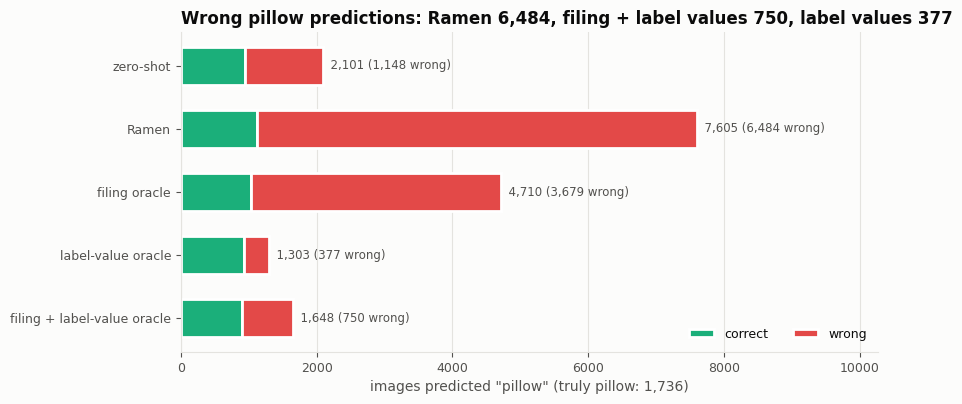

In [25]:
wrong = {n: int(((exp.results[n].pred == exp.classes.index('pillow')) & ~exp.results[n].correct).sum())
         for n in FULL_RUNS}
plots.plot_class_predictions(exp, 'pillow', list(FULL_RUNS),
                             title=f"Wrong pillow predictions: Ramen {wrong['Ramen']:,}, filing + label values "
                                   f"{wrong['labeloracle_true_ce']:,}, label values {wrong['labeloracle_zs_ce']:,}");

## 7. Interpretation

**What the numbers say (seed 0; noise floor 0.11 points).**

| | entropy values (Ramen) | true-label CE values (ORACLE) | effect of label values |
|---|---|---|---|
| **zero-shot filing (Ramen)** | 56.80 (Ramen) | **58.50 (+1.70, +12,207 images)** | +1.70 |
| **true-label filing (ORACLE)** | 55.29 (−1.50) | 56.54 (−0.25, −1,007 images) | +1.25 |
| **effect of true-label filing** | −1.50 | −1.96 | |

- **H1 is rejected.** Filing *and* values both from the true label do **not** beat Ramen: −0.25 points
  (−1,007 images). Quickdraw is 17.34% against Ramen's 17.54%.
- **H2 is half right.** Label values help under either filing: +1.70 (zero-shot filing) and +1.25 (true-label
  filing). Filing by true label hurts just as much: −1.50 and −1.96. With zero-shot filing and label values,
  accuracy rises in every domain: infograph +0.58 up to quickdraw +4.02.
- **H3 holds.** The *pillow* sink disappears once values carry labels: 377 wrong *pillow* predictions
  (zero-shot filing) and 750 (true-label filing), against Ramen's 6,484 and zero-shot's 1,148.

**What this says about the filing oracle.** Its loss has two causes. The first, values that sharpen zero-shot
mistakes, is real: label values recover 1.25 points. The second is that **true-label filing makes retrieval
worse, whatever the values**. Section 5 shows why. Ramen's update is a vote of the 10 nearest entries from each
of about 345 queues. It is spread over about 235 classes, and the image's own class gets only about 2.5% of the
weight under either filing.

- **With true-label filing, every queue holds its class from every domain.** A quickdraw image therefore gets
  ten quickdraw sketches from each of 345 classes: 100% of its update comes from its own domain, and the weight
  is spread over even more classes (276).
- **Its own class leads the vote less often.** That happens for 39% of images, against 46% with zero-shot
  filing; on quickdraw, 11% against 20%.
- **Zero-shot filing crowds look-alike images into a few queues,** and the top-10 cut limits how much they can
  outvote the rest.

**Filing by the adapted prediction (section 4.4) does not help either.** Without labels it scores −0.27
points vs Ramen (−2,639 images) and −0.21 vs its timing control, almost all of it on quickdraw (15.94% vs
17.51%). Moving the write after prediction costs only −0.05 by itself, so neither self-retrieval nor the
same-batch entries matter much. With label values, adapted filing gives +1.26 vs +1.86 for zero-shot filing with
the same timing. Like true-label filing, a "better" filing label lowers accuracy; the stored values, not the
queue labels, carry the effect.

**What it does not show.**
- One seed.
- **These are oracles, not methods.**
- The vote-share measure counts weight, not gradient direction.
- **Only the first 168,502 images (28%) were ever stored.** Ramen's fp16 counter freezes the full queues, so
  every run here works with a fixed memory after that point. The label-value gain is what labels on those
  images buy.

**Ceiling, and what limits it (sections 4.5, 5.2, 5.3).** With the true labels of earlier images, Ramen's
retrieval yields +1.70 points. Retrieving the k nearest entries of the whole cache instead of 10 per queue raises
it:

| retrieval (label values) | vs Ramen |
|---|---|
| 10 per queue (Ramen) | +1.70 (+12,207 images) |
| 10 nearest overall | **+2.86 (+22,366)** |
| 100 nearest overall | +2.54 (+18,947) |
| 1,000 nearest overall | +1.84 (+12,264) |
| 100 nearest overall, **no labels** | +0.04 (−1,068) |

- **The queue-averaged vote is part of the limit on DomainNet:** global top-10 adds +1.16 points over per-queue
  retrieval, ten times the floor, and the gain shrinks as k grows toward Ramen's spread-out vote. **Most of it is
  quickdraw:** 21.56% → 27.04% (+5.48) over per-queue label values; the other five domains move by −0.17 to +0.45.
- **It is not a near-copy leak** (section 5.3; on ImageNet-C the same pattern was one). Of 2,000 sampled images,
  only 19 (0.9%) have another cache entry within distance 0.1. Without them the sample's gain over per-queue
  retrieval moves from +2.70 to +2.62 points.
- **The neighbours themselves are the next limit** (section 5.2). On average only 4.5 of an image's 10 nearest
  entries share its class (quickdraw 2.1), and their label vote is right for 57.6% of the sampled images against
  51.6% for zero-shot. That puts the reachable accuracy for this retrieval well below 100%.
- **Without labels, global retrieval does nothing** (+0.04): it only helps once the values carry labels.

**Next step.** The open question is no longer the vote but where correct labels could come from without
supervision. Global retrieval is only worth using if a label-free value can be made to point toward the right
class more often than the entropy gradient does.


## 8. Glossary

| term | meaning |
|---|---|
| zero-shot | CLIP classifies by cosine similarity between the image embedding and each class's text embedding. No adaptation. |
| Ramen | test-time adaptation. Each image is written into a class queue with its own gradient; the gradients of the nearest stored entries are retrieved, one signSGD step is taken on the image encoder's LayerNorm parameters, the image is predicted, and the parameters are reset. |
| cache / queue / entry | Ramen's memory: one queue of up to 300 entries per class. An entry is (zero-shot feature, value = a gradient, zero-shot entropy, arrival counter). |
| filing | which queue an image is written to: its zero-shot prediction (Ramen) or its true label (oracle). |
| value | the gradient an entry stores. Ramen: the image's own entropy gradient (sharpens the zero-shot prediction). Label oracle: the cross-entropy gradient toward the true label, stored once the image has been predicted. |
| filing oracle | `oracle_file_true`: filed by true label, Ramen's entropy values. |
| label-value oracle | `labeloracle_zs_ce`: filed by zero-shot prediction, label values. |
| filing + label-value oracle | `labeloracle_true_ce`: both. |
| oracle | a run that uses ground-truth labels: an upper bound on what a method could reach, not a method. |
| retrieval weight | e^(−H)·e^(−β·d) for an entry with zero-shot entropy H at feature distance d; the top 10 per non-empty queue, queues averaged. |
| noise floor | 2 × (max − min) of Ramen's domain-averaged accuracy over seeds 0–4; a change must exceed it to count. |
| fixed / broken | images a run gets right that the baseline got wrong / wrong that the baseline got right. |
| sink | a class a model predicts for many images of other classes (here *pillow*). |
| domain average | the mean of the 6 per-domain accuracies (the headline convention). |
| global top-k retrieval | the k nearest entries of the whole cache, whatever their queue (`RamenGlobalRetrieval`, `retrieval: global_knn`), instead of 10 per queue. |
| label vote | the retrieval-weighted vote of the retrieved entries' true labels: the class a label-value update pushes toward most. |
| near-copy | another cache entry within feature distance 0.1 of the image (cosine similarity above 0.995); with label values it would leak the image's label. |
